In [1]:
!pip install -q tensorflow-model-optimization

import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tensorflow_model_optimization as tfmot

print("TensorFlow:", tf.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.7/242.7 kB 1.6 MB/s eta 0:00:00
TensorFlow: 2.20.0


In [2]:
from google.colab import files

uploaded = files.upload()

Saving circular_Raw Data.csv to circular_Raw Data.csv
Saving shake_Raw Data.csv to shake_Raw Data.csv
Saving still_Raw Data.csv to still_Raw Data.csv
Saving walk_Raw Data.csv to walk_Raw Data.csv


In [4]:
# ============================================
# PART 2 — LOAD PHYPhOX SENSOR DATA
# ============================================

import pandas as pd
from google.colab import files
import os

# Upload the four CSV files
uploaded = files.upload()

# Display uploaded CSV files
print("Uploaded files:")
for file in uploaded.keys():
    print(" -", file)

# Load the CSV files
circular = pd.read_csv("circular_Raw Data.csv")
shake = pd.read_csv("shake_Raw Data.csv")
still = pd.read_csv("still_Raw Data.csv")
walk = pd.read_csv("walk_Raw Data.csv")

# Display dataset sizes
print("\nDataset sizes:")
print("Circular:", circular.shape)
print("Shake:", shake.shape)
print("Still:", still.shape)
print("Walk:", walk.shape)

# Display column names
print("\nColumn names:")
print(circular.columns.tolist())

# Display first five rows of each dataset
print("\nCircular data:")
display(circular.head())

print("\nShake data:")
display(shake.head())

print("\nStill data:")
display(still.head())

print("\nWalk data:")
display(walk.head())

Saving circular_Raw Data.csv to circular_Raw Data.csv
Saving shake_Raw Data.csv to shake_Raw Data.csv
Saving still_Raw Data.csv to still_Raw Data.csv
Saving walk_Raw Data.csv to walk_Raw Data.csv
Uploaded files:
 - circular_Raw Data.csv
 - shake_Raw Data.csv
 - still_Raw Data.csv
 - walk_Raw Data.csv

Dataset sizes:
Circular: (12203, 5)
Shake: (12149, 5)
Still: (12113, 5)
Walk: (12217, 5)

Column names:
['Time (s)', 'Acceleration x (m/s^2)', 'Acceleration y (m/s^2)', 'Acceleration z (m/s^2)', 'Absolute acceleration (m/s^2)']

Circular data:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,-0.001655,-1.193768,7.539971,7.013366,10.366462
1,0.008352,-1.496288,7.480095,6.757398,10.190835
2,0.018359,-1.737287,7.343429,6.332581,9.851178
3,0.028366,-1.839375,7.247179,5.871390,9.506742
4,0.038372,-1.867367,7.234905,5.650450,9.367950



Shake data:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,-0.001757,0.175884,7.134015,7.701634,10.499537
1,0.008248,0.275427,7.111112,7.607480,10.417175
2,0.018254,0.088017,7.093299,7.072343,10.017019
3,0.028259,-0.199834,7.009174,6.595734,9.626638
4,0.038265,-0.303569,6.907536,6.495742,9.486879



Still data:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,0.012732,0.335452,0.370629,9.755663,9.768462
1,0.022737,0.497416,0.317490,9.687704,9.705660
2,0.032742,0.508044,0.346829,9.664652,9.684209
3,0.042747,0.439336,0.360301,9.727821,9.744400
4,0.052752,0.512684,0.339494,9.801468,9.820737



Walk data:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,0.002494,1.037343,1.475332,8.981024,9.160321
1,0.012502,1.012644,1.483864,8.737331,8.920104
2,0.022509,1.007255,1.414409,8.650661,8.823211
3,0.032517,0.938548,1.395997,8.746611,8.906901
4,0.042524,0.811762,1.366957,8.967402,9.107241


Column names:
['Acceleration x (m/s^2)', 'Acceleration y (m/s^2)', 'Acceleration z (m/s^2)', 'label']

Data types:
Acceleration x (m/s^2)    float64
Acceleration y (m/s^2)    float64
Acceleration z (m/s^2)    float64
label                      object
dtype: object

Missing values:

Circular:
Acceleration x (m/s^2)    0
Acceleration y (m/s^2)    0
Acceleration z (m/s^2)    0
label                     0
dtype: int64

Shake:
Acceleration x (m/s^2)    0
Acceleration y (m/s^2)    0
Acceleration z (m/s^2)    0
label                     0
dtype: int64

Still:
Acceleration x (m/s^2)    0
Acceleration y (m/s^2)    0
Acceleration z (m/s^2)    0
label                     0
dtype: int64

Walk:
Acceleration x (m/s^2)    0
Acceleration y (m/s^2)    0
Acceleration z (m/s^2)    0
label                     0
dtype: int64

Combined dataset shape:
(48682, 4)

First five rows:


,Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),label
0,-1.193768,7.539971,7.013366,circular
1,-1.496288,7.480095,6.757398,circular
2,-1.737287,7.343429,6.332581,circular
3,-1.839375,7.247179,5.871390,circular
4,-1.867367,7.234905,5.650450,circular



Number of samples in each activity:
label
walk        12217
circular    12203
shake       12149
still       12113
Name: count, dtype: int64

Missing values in final dataset:
Acceleration x (m/s^2)    0
Acceleration y (m/s^2)    0
Acceleration z (m/s^2)    0
label                     0
dtype: int64


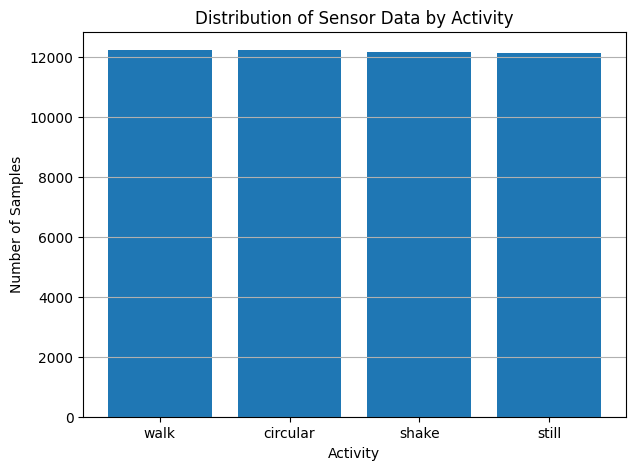

In [15]:
# Check the column names

print("Column names:")
print(circular.columns.tolist())

# Check the data types

print("\nData types:")
print(circular.dtypes)

# Check for missing values

print("\nMissing values:")

print("\nCircular:")
print(circular.isnull().sum())

print("\nShake:")
print(shake.isnull().sum())

print("\nStill:")
print(still.isnull().sum())

print("\nWalk:")
print(walk.isnull().sum())

# Remove rows containing missing values

circular = circular.dropna().reset_index(drop=True)
shake = shake.dropna().reset_index(drop=True)
still = still.dropna().reset_index(drop=True)
walk = walk.dropna().reset_index(drop=True)

# Select the sensor features that will be used by the model

features = [
    "Acceleration x (m/s^2)",
    "Acceleration y (m/s^2)",
    "Acceleration z (m/s^2)"
]

circular = circular[features].copy()
shake = shake[features].copy()
still = still[features].copy()
walk = walk[features].copy()

# Assign activity labels

circular["label"] = "circular"
shake["label"] = "shake"
still["label"] = "still"
walk["label"] = "walk"

# Combine all four datasets

data = pd.concat(
    [circular, shake, still, walk],
    ignore_index=True
)

# Display the combined dataset

print("\nCombined dataset shape:")
print(data.shape)

print("\nFirst five rows:")
display(data.head())

# Check the number of samples for each activity

class_counts = data["label"].value_counts()

print("\nNumber of samples in each activity:")
print(class_counts)

# Check that there are no missing values remaining

print("\nMissing values in final dataset:")
print(data.isnull().sum())

# Visualize the number of samples in each activity

plt.figure(figsize=(7, 5))

plt.bar(
    class_counts.index,
    class_counts.values
)

plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.title("Distribution of Sensor Data by Activity")
plt.grid(axis="y")

plt.show()

Windows created:
Circular: 243
Shake: 241
Still: 241
Walk: 243

Total windows: 968

X shape: (968, 100, 3)
y shape: (968,)

Activity encoding:
0 = circular
1 = shake
2 = still
3 = walk

Training data shape: (774, 100, 3)
Testing data shape: (194, 100, 3)

Final dataset:
Training shape: (774, 100, 3)
Testing shape: (194, 100, 3)

Training label distribution:
[194 193 193 194]

Testing label distribution:
[49 48 48 49]

Normalized training mean:
[ 7.7845186e-08 -8.7458409e-07 -6.7997016e-06]

Normalized training standard deviation:
[1.0001825  0.99991477 1.000009  ]


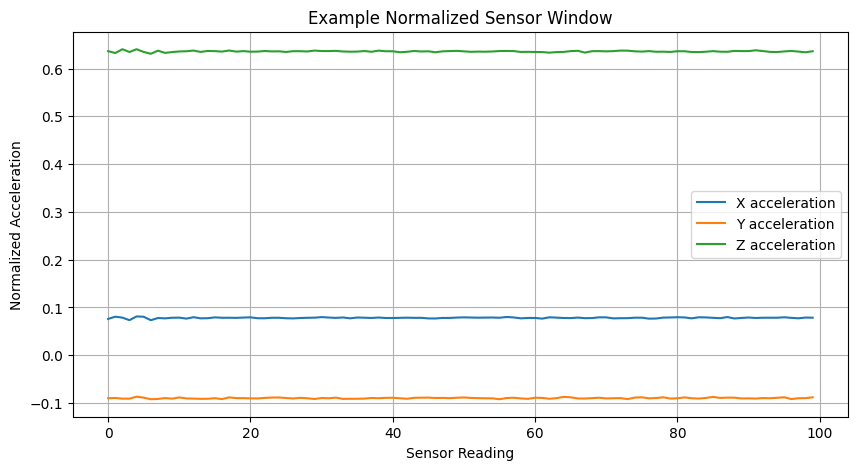

In [16]:
# WINDOWING & DATASET PREPARATION

import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Set the window size and overlap

WINDOW_SIZE = 100
STEP_SIZE = 50

FEATURES = [
    "Acceleration x (m/s^2)",
    "Acceleration y (m/s^2)",
    "Acceleration z (m/s^2)"
]

# Create fixed-length sensor windows

def create_windows(df, label, window_size=100, step_size=50):

    values = df[FEATURES].values.astype(np.float32)

    X_windows = []
    y_labels = []

    for start in range(
        0,
        len(values) - window_size + 1,
        step_size
    ):

        window = values[
            start:start + window_size
        ]

        X_windows.append(window)
        y_labels.append(label)

    return np.array(X_windows), np.array(y_labels)


# Create windows for each activity

X_circular, y_circular = create_windows(
    circular,
    "circular",
    WINDOW_SIZE,
    STEP_SIZE
)

X_shake, y_shake = create_windows(
    shake,
    "shake",
    WINDOW_SIZE,
    STEP_SIZE
)

X_still, y_still = create_windows(
    still,
    "still",
    WINDOW_SIZE,
    STEP_SIZE
)

X_walk, y_walk = create_windows(
    walk,
    "walk",
    WINDOW_SIZE,
    STEP_SIZE
)

# Combine all activity windows

X = np.concatenate(
    [
        X_circular,
        X_shake,
        X_still,
        X_walk
    ],
    axis=0
)

y = np.concatenate(
    [
        y_circular,
        y_shake,
        y_still,
        y_walk
    ],
    axis=0
)

# Display the number of windows created

print("Windows created:")
print("Circular:", len(X_circular))
print("Shake:", len(X_shake))
print("Still:", len(X_still))
print("Walk:", len(X_walk))

print("\nTotal windows:", len(X))

print("\nX shape:", X.shape)
print("y shape:", y.shape)

# Encode the activity labels into numbers

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("\nActivity encoding:")

for number, name in enumerate(label_encoder.classes_):
    print(number, "=", name)

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# Calculate normalization values using training data only

mean = X_train.mean(
    axis=(0, 1),
    keepdims=True
)

std = X_train.std(
    axis=(0, 1),
    keepdims=True
)

std = np.where(std == 0, 1, std)

# Normalize the training and testing data

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Display final dataset information

print("\nFinal dataset:")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining label distribution:")
print(np.bincount(y_train))

print("\nTesting label distribution:")
print(np.bincount(y_test))

# Verify normalization

print("\nNormalized training mean:")
print(X_train.mean(axis=(0, 1)))

print("\nNormalized training standard deviation:")
print(X_train.std(axis=(0, 1)))

# Visualize one example sensor window

plt.figure(figsize=(10, 5))

plt.plot(
    X_train[0, :, 0],
    label="X acceleration"
)

plt.plot(
    X_train[0, :, 1],
    label="Y acceleration"
)

plt.plot(
    X_train[0, :, 2],
    label="Z acceleration"
)

plt.xlabel("Sensor Reading")
plt.ylabel("Normalized Acceleration")
plt.title("Example Normalized Sensor Window")
plt.legend()
plt.grid()

plt.show()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 300)               0         
                                                                 
 dense_2 (Dense)             (None, 64)                19264     
                                                                 
 dense_3 (Dense)             (None, 32)                2080      
                                                                 
 dense_4 (Dense)             (None, 4)                 132       
                                                                 
Total params: 21476 (83.89 KB)
Trainable params: 21476 (83.89 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/20
20/20 [==============================] - 1s 11ms/step - loss: 0.6805 - accuracy: 0.8126 - val_loss: 0.3063 - val_accuracy: 0.9548
Epoch 2/2

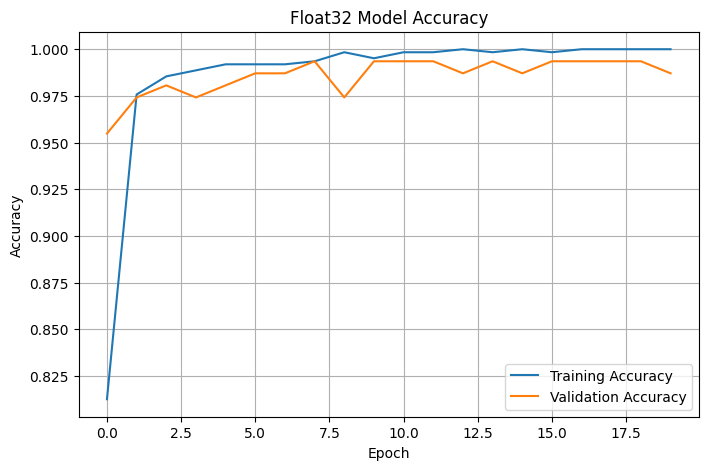

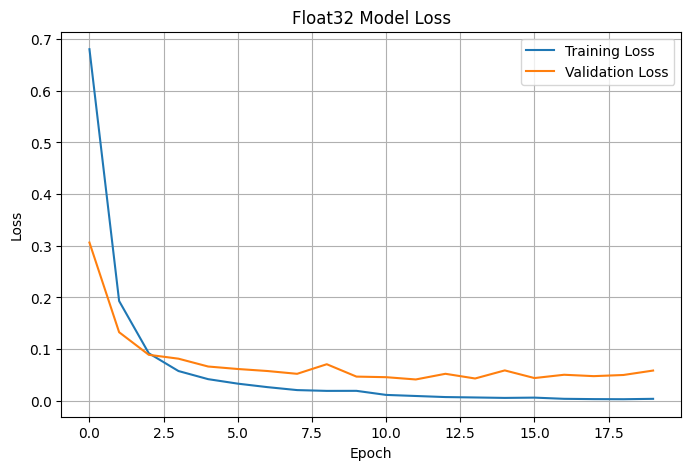

In [17]:
# FLOAT32 BASELINE MODEL

import tensorflow as tf
import matplotlib.pyplot as plt

# Build the baseline model

model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(WINDOW_SIZE, 3)
    ),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        64,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        32,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        4,
        activation="softmax"
    )
])

# Compile the model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture

model.summary()

# Train the Float32 model

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluate the model on the test dataset

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nFLOAT32 BASELINE RESULTS")

print(f"Test Loss: {test_loss:.4f}")

print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Float32 Model Accuracy")
plt.legend()
plt.grid()

plt.show()

# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Float32 Model Loss")
plt.legend()
plt.grid()

plt.show()

In [18]:
# FLOAT32 TFLITE MODEL & BASELINE EVALUATION

import tensorflow as tf
import numpy as np
import os
import time

# Convert the trained Float32 model to TFLite

converter = tf.lite.TFLiteConverter.from_keras_model(model)

float32_tflite = converter.convert()

# Save the TFLite model

float32_model_path = "float32_baseline.tflite"

with open(float32_model_path, "wb") as f:
    f.write(float32_tflite)

print("Float32 TFLite model created successfully.")

# Calculate the model size

float32_size = (
    os.path.getsize(float32_model_path) / 1024
)

print(f"Float32 model size: {float32_size:.2f} KB")

# Load the TFLite model

interpreter = tf.lite.Interpreter(
    model_path=float32_model_path
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Display input and output information

print("\nInput shape:")
print(input_details[0]["shape"])

print("\nInput data type:")
print(input_details[0]["dtype"])

print("\nOutput shape:")
print(output_details[0]["shape"])

print("\nOutput data type:")
print(output_details[0]["dtype"])

# Evaluate TFLite accuracy and latency

correct = 0
total_inference_time = 0

for i in range(len(X_test)):

    sample = X_test[i:i+1].astype(np.float32)

    start_time = time.perf_counter()

    interpreter.set_tensor(
        input_details[0]["index"],
        sample
    )

    interpreter.invoke()

    end_time = time.perf_counter()

    total_inference_time += (
        end_time - start_time
    )

    output = interpreter.get_tensor(
        output_details[0]["index"]
    )

    prediction = np.argmax(output)

    if prediction == y_test[i]:
        correct += 1

# Calculate accuracy

float32_tflite_accuracy = (
    correct / len(X_test)
)

# Calculate average inference latency

float32_latency = (
    total_inference_time / len(X_test)
) * 1000

# Display baseline results

print("\nFLOAT32 TFLITE RESULTS")

print(
    f"Model Size: "
    f"{float32_size:.2f} KB"
)

print(
    f"Test Accuracy: "
    f"{float32_tflite_accuracy * 100:.2f}%"
)

print(
    f"Average Latency: "
    f"{float32_latency:.4f} ms"
)

Float32 TFLite model created successfully.
Float32 model size: 86.14 KB

Input shape:
[  1 100   3]

Input data type:
<class 'numpy.float32'>

Output shape:
[1 4]

Output data type:
<class 'numpy.float32'>

FLOAT32 TFLITE RESULTS
Model Size: 86.14 KB
Test Accuracy: 100.00%
Average Latency: 0.0075 ms


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [19]:
# POST-TRAINING QUANTIZATION (PTQ)

import tensorflow as tf
import numpy as np
import os

# Create a representative dataset for calibration

def representative_dataset():

    num_samples = min(200, len(X_train))

    for i in range(num_samples):

        sample = X_train[i:i+1].astype(np.float32)

        yield [sample]

print(
    "Representative samples:",
    min(200, len(X_train))
)

# Create the TFLite converter

converter = tf.lite.TFLiteConverter.from_keras_model(
    model
)

# Enable post-training quantization

converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]

# Provide the representative dataset

converter.representative_dataset = (
    representative_dataset
)

# Require INT8 operations

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

# Set INT8 input and output

converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# Convert the model

ptq_tflite = converter.convert()

# Save the PTQ model

ptq_model_path = "ptq_full_int8.tflite"

with open(ptq_model_path, "wb") as f:
    f.write(ptq_tflite)

print("\nPTQ full INT8 model created successfully.")

# Calculate the model size

ptq_size = (
    os.path.getsize(ptq_model_path) / 1024
)

print(
    f"PTQ INT8 model size: "
    f"{ptq_size:.2f} KB"
)

# Load the PTQ model

ptq_interpreter = tf.lite.Interpreter(
    model_path=ptq_model_path
)

ptq_interpreter.allocate_tensors()

ptq_input_details = (
    ptq_interpreter.get_input_details()
)

ptq_output_details = (
    ptq_interpreter.get_output_details()
)

# Display input and output information

print("\nPTQ input shape:")
print(ptq_input_details[0]["shape"])

print("\nPTQ input data type:")
print(ptq_input_details[0]["dtype"])

print("\nPTQ output shape:")
print(ptq_output_details[0]["shape"])

print("\nPTQ output data type:")
print(ptq_output_details[0]["dtype"])

# Display quantization parameters

print("\nInput quantization:")
print(
    ptq_input_details[0]["quantization"]
)

print("\nOutput quantization:")
print(
    ptq_output_details[0]["quantization"]
)

Representative samples: 200

PTQ full INT8 model created successfully.
PTQ INT8 model size: 26.22 KB

PTQ input shape:
[  1 100   3]

PTQ input data type:
<class 'numpy.int8'>

PTQ output shape:
[1 4]

PTQ output data type:
<class 'numpy.int8'>

Input quantization:
(0.06445866823196411, 5)

Output quantization:
(0.00390625, -128)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [20]:
# PTQ INT8 EVALUATION

import tensorflow as tf
import numpy as np
import time
import os

# Load the PTQ INT8 model

ptq_interpreter = tf.lite.Interpreter(
    model_path="ptq_full_int8.tflite"
)

ptq_interpreter.allocate_tensors()

input_details = ptq_interpreter.get_input_details()
output_details = ptq_interpreter.get_output_details()

# Get INT8 quantization parameters

input_scale, input_zero_point = (
    input_details[0]["quantization"]
)

output_scale, output_zero_point = (
    output_details[0]["quantization"]
)

print("Input scale:", input_scale)
print("Input zero point:", input_zero_point)

print("\nOutput scale:", output_scale)
print("Output zero point:", output_zero_point)

print("\nInput data type:")
print(input_details[0]["dtype"])

print("\nOutput data type:")
print(output_details[0]["dtype"])

# Run inference on the test dataset

correct = 0
total_inference_time = 0

for i in range(len(X_test)):

    sample = X_test[i:i+1].astype(np.float32)

    # Convert Float32 input to INT8

    quantized_sample = np.round(
        sample / input_scale
        + input_zero_point
    )

    quantized_sample = np.clip(
        quantized_sample,
        -128,
        127
    ).astype(np.int8)

    # Measure inference latency

    start_time = time.perf_counter()

    ptq_interpreter.set_tensor(
        input_details[0]["index"],
        quantized_sample
    )

    ptq_interpreter.invoke()

    end_time = time.perf_counter()

    total_inference_time += (
        end_time - start_time
    )

    # Get the model output

    output = ptq_interpreter.get_tensor(
        output_details[0]["index"]
    )

    prediction = np.argmax(output)

    # Check whether the prediction is correct

    if prediction == y_test[i]:
        correct += 1

# Calculate PTQ accuracy

ptq_accuracy = (
    correct / len(X_test)
)

# Calculate average latency

ptq_latency = (
    total_inference_time / len(X_test)
) * 1000

# Calculate model size

ptq_size = (
    os.path.getsize("ptq_full_int8.tflite")
    / 1024
)

# Calculate changes compared with Float32

size_reduction = (
    (float32_size - ptq_size)
    / float32_size
) * 100

accuracy_difference = (
    ptq_accuracy
    - float32_tflite_accuracy
) * 100

latency_difference = (
    (ptq_latency - float32_latency)
    / float32_latency
) * 100

# Display PTQ results

print("\nPTQ INT8 RESULTS")

print(
    f"Model Size: "
    f"{ptq_size:.2f} KB"
)

print(
    f"Test Accuracy: "
    f"{ptq_accuracy * 100:.2f}%"
)

print(
    f"Average Latency: "
    f"{ptq_latency:.4f} ms"
)

print(
    f"Size Reduction: "
    f"{size_reduction:.2f}%"
)

print(
    f"Accuracy Difference: "
    f"{accuracy_difference:+.2f} percentage points"
)

print(
    f"Latency Difference: "
    f"{latency_difference:+.2f}%"
)

# Create a comparison table

comparison_ptq = pd.DataFrame({
    "Model": [
        "Float32",
        "PTQ INT8"
    ],
    "Size (KB)": [
        float32_size,
        ptq_size
    ],
    "Accuracy (%)": [
        float32_tflite_accuracy * 100,
        ptq_accuracy * 100
    ],
    "Latency (ms)": [
        float32_latency,
        ptq_latency
    ]
})

print("\nFloat32 vs PTQ comparison:")

display(comparison_ptq)

Input scale: 0.06445866823196411
Input zero point: 5

Output scale: 0.00390625
Output zero point: -128

Input data type:
<class 'numpy.int8'>

Output data type:
<class 'numpy.int8'>

PTQ INT8 RESULTS
Model Size: 26.22 KB
Test Accuracy: 100.00%
Average Latency: 0.0105 ms
Size Reduction: 69.56%
Accuracy Difference: +0.00 percentage points
Latency Difference: +40.15%

Float32 vs PTQ comparison:


,Model,Size (KB),Accuracy (%),Latency (ms)
0,Float32,86.140625,100.0,0.007500
1,PTQ INT8,26.218750,100.0,0.010511


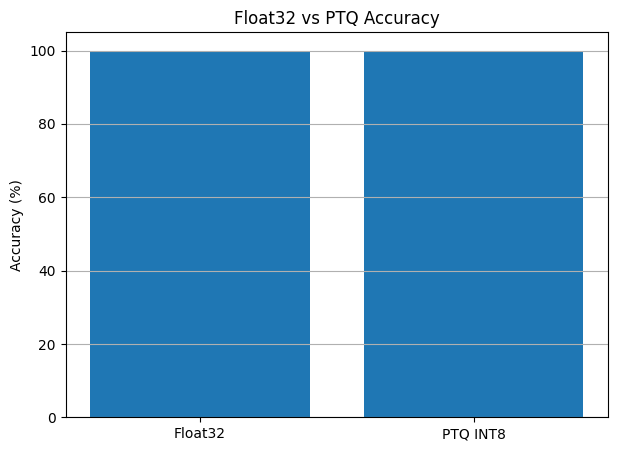

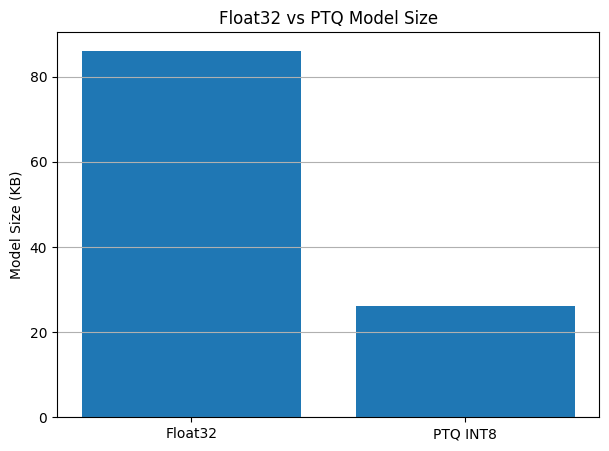

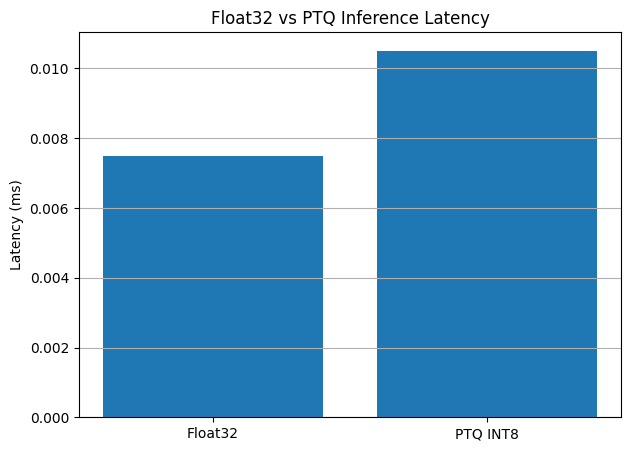

In [21]:
# PTQ VISUAL COMPARISON

models = [
    "Float32",
    "PTQ INT8"
]

accuracies = [
    float32_tflite_accuracy * 100,
    ptq_accuracy * 100
]

sizes = [
    float32_size,
    ptq_size
]

latencies = [
    float32_latency,
    ptq_latency
]

# Accuracy comparison

plt.figure(figsize=(7, 5))

plt.bar(models, accuracies)

plt.ylabel("Accuracy (%)")
plt.title("Float32 vs PTQ Accuracy")
plt.grid(axis="y")

plt.show()

# Model size comparison

plt.figure(figsize=(7, 5))

plt.bar(models, sizes)

plt.ylabel("Model Size (KB)")
plt.title("Float32 vs PTQ Model Size")
plt.grid(axis="y")

plt.show()

# Latency comparison

plt.figure(figsize=(7, 5))

plt.bar(models, latencies)

plt.ylabel("Latency (ms)")
plt.title("Float32 vs PTQ Inference Latency")
plt.grid(axis="y")

plt.show()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 quantize_layer_2 (Quantize  (None, 100, 3)            3         
 Layer)                                                          
                                                                 
 quant_flatten (QuantizeWra  (None, 300)               1         
 pperV2)                                                         
                                                                 
 quant_dense_2 (QuantizeWra  (None, 64)                19269     
 pperV2)                                                         
                                                                 
 quant_dense_3 (QuantizeWra  (None, 32)                2085      
 pperV2)                                                         
                                                                 
 quant_dense_4 (QuantizeWra  (None, 4)                

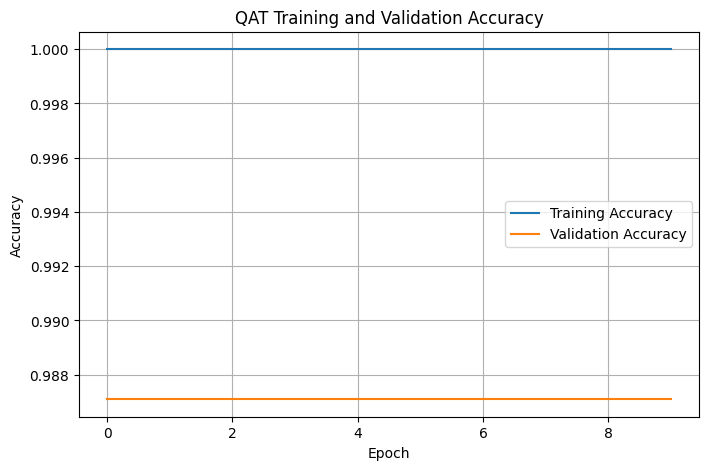

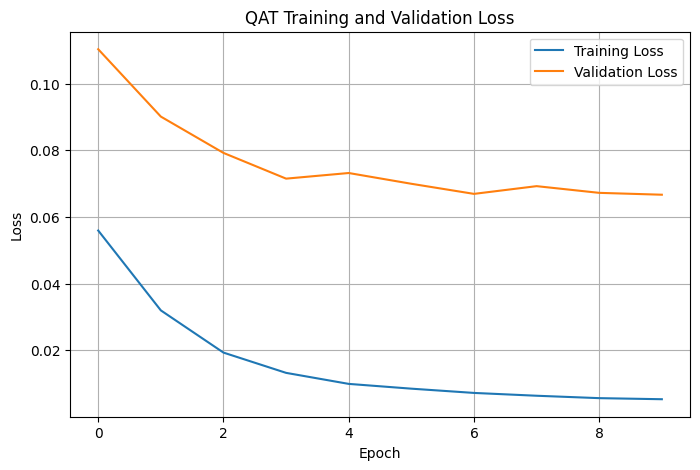

In [22]:
# QUANTIZATION-AWARE TRAINING (QAT)

import tensorflow as tf
import tensorflow_model_optimization as tfmot
import matplotlib.pyplot as plt

# Create a fresh copy of the trained Float32 model

qat_base_model = tf.keras.models.clone_model(model)

qat_base_model.set_weights(
    model.get_weights()
)

# Apply Quantization-Aware Training

qat_model = tfmot.quantization.keras.quantize_model(
    qat_base_model
)

# Compile the QAT model

qat_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the QAT model architecture

qat_model.summary()

# Fine-tune the QAT model

qat_history = qat_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluate the QAT model

qat_loss, qat_accuracy = qat_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nQAT RESULTS")

print(
    f"Test Loss: "
    f"{qat_loss:.4f}"
)

print(
    f"Test Accuracy: "
    f"{qat_accuracy * 100:.2f}%"
)

# Plot QAT training accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    qat_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    qat_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("QAT Training and Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

# Plot QAT training loss

plt.figure(figsize=(8, 5))

plt.plot(
    qat_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    qat_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("QAT Training and Validation Loss")
plt.legend()
plt.grid()

plt.show()

In [24]:
# QAT INT8 TFLITE CONVERSION & EVALUATION

import tensorflow as tf
import numpy as np
import os
import time

# Create the TFLite converter from the QAT model

converter = tf.lite.TFLiteConverter.from_keras_model(
    qat_model
)

# Enable optimizations

converter.optimizations = [
    tf.lite.Optimize.DEFAULT
]

# Create representative dataset

def qat_representative_dataset():

    num_samples = min(200, len(X_train))

    for i in range(num_samples):

        sample = X_train[i:i+1].astype(np.float32)

        yield [sample]

# Provide representative dataset

converter.representative_dataset = (
    qat_representative_dataset
)

# Require INT8 operations

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

# Set INT8 input and output

converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# Convert the QAT model

qat_tflite = converter.convert()

# Save the QAT INT8 model

qat_model_path = "qat_full_int8.tflite"

with open(qat_model_path, "wb") as f:
    f.write(qat_tflite)

print("QAT INT8 TFLite model created successfully.")

# Calculate model size

qat_size = (
    os.path.getsize(qat_model_path) / 1024
)

print(
    f"QAT INT8 model size: "
    f"{qat_size:.2f} KB"
)

# Load the QAT INT8 model

qat_interpreter = tf.lite.Interpreter(
    model_path=qat_model_path
)

qat_interpreter.allocate_tensors()

qat_input_details = (
    qat_interpreter.get_input_details()
)

qat_output_details = (
    qat_interpreter.get_output_details()
)

# Display model information

print("\nQAT input shape:")
print(qat_input_details[0]["shape"])

print("\nQAT input data type:")
print(qat_input_details[0]["dtype"])

print("\nQAT output shape:")
print(qat_output_details[0]["shape"])

print("\nQAT output data type:")
print(qat_output_details[0]["dtype"])

# Get input quantization parameters

qat_input_scale, qat_input_zero_point = (
    qat_input_details[0]["quantization"]
)

print("\nQAT input quantization:")
print(
    "Scale:",
    qat_input_scale
)

print(
    "Zero point:",
    qat_input_zero_point
)

# Evaluate the QAT INT8 model

correct = 0
total_inference_time = 0

for i in range(len(X_test)):

    sample = X_test[i:i+1].astype(np.float32)

    # Convert Float32 input to INT8

    quantized_sample = np.round(
        sample / qat_input_scale
        + qat_input_zero_point
    )

    quantized_sample = np.clip(
        quantized_sample,
        -128,
        127
    ).astype(np.int8)

    # Start latency measurement

    start_time = time.perf_counter()

    qat_interpreter.set_tensor(
        qat_input_details[0]["index"],
        quantized_sample
    )

    qat_interpreter.invoke()

    end_time = time.perf_counter()

    total_inference_time += (
        end_time - start_time
    )

    # Get model output

    output = qat_interpreter.get_tensor(
        qat_output_details[0]["index"]
    )

    prediction = np.argmax(output)

    # Check prediction

    if prediction == y_test[i]:
        correct += 1

# Calculate accuracy

qat_tflite_accuracy = (
    correct / len(X_test)
)

# Calculate average latency

qat_latency = (
    total_inference_time / len(X_test)
) * 1000

# Calculate size reduction

qat_size_reduction = (
    (float32_size - qat_size)
    / float32_size
) * 100

# Display results

print("\nQAT INT8 RESULTS")

print(
    f"Model Size: "
    f"{qat_size:.2f} KB"
)

print(
    f"Test Accuracy: "
    f"{qat_tflite_accuracy * 100:.2f}%"
)

print(
    f"Average Latency: "
    f"{qat_latency:.4f} ms"
)

print(
    f"Size Reduction: "
    f"{qat_size_reduction:.2f}%"
)

QAT INT8 TFLite model created successfully.
QAT INT8 model size: 24.33 KB

QAT input shape:
[  1 100   3]

QAT input data type:
<class 'numpy.int8'>

QAT output shape:
[1 4]

QAT output data type:
<class 'numpy.int8'>

QAT input quantization:
Scale: 0.06445866823196411
Zero point: 5

QAT INT8 RESULTS
Model Size: 24.33 KB
Test Accuracy: 100.00%
Average Latency: 0.0054 ms
Size Reduction: 71.76%


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [25]:
# FINAL COMPARISON & RESULTS

import pandas as pd
import matplotlib.pyplot as plt

# Create the final comparison table

final_comparison = pd.DataFrame({
    "Model": [
        "Float32",
        "PTQ INT8",
        "QAT INT8"
    ],
    "Model Size (KB)": [
        float32_size,
        ptq_size,
        qat_size
    ],
    "Accuracy (%)": [
        float32_tflite_accuracy * 100,
        ptq_accuracy * 100,
        qat_tflite_accuracy * 100
    ],
    "Latency (ms)": [
        float32_latency,
        ptq_latency,
        qat_latency
    ]
})

# Display the final results

display(final_comparison)

# Calculate percentage changes

ptq_size_reduction = (
    (float32_size - ptq_size)
    / float32_size
) * 100

qat_size_reduction = (
    (float32_size - qat_size)
    / float32_size
) * 100

ptq_accuracy_change = (
    ptq_accuracy
    - float32_tflite_accuracy
) * 100

qat_accuracy_change = (
    qat_tflite_accuracy
    - float32_tflite_accuracy
) * 100

print("\nMODEL COMPARISON")

print(
    f"PTQ size reduction: "
    f"{ptq_size_reduction:.2f}%"
)

print(
    f"QAT size reduction: "
    f"{qat_size_reduction:.2f}%"
)

print(
    f"PTQ accuracy change: "
    f"{ptq_accuracy_change:+.2f} percentage points"
)

print(
    f"QAT accuracy change: "
    f"{qat_accuracy_change:+.2f} percentage points"
)

,Model,Model Size (KB),Accuracy (%),Latency (ms)
0,Float32,86.140625,100.0,0.007500
1,PTQ INT8,26.218750,100.0,0.010511
2,QAT INT8,24.328125,100.0,0.005426



MODEL COMPARISON
PTQ size reduction: 69.56%
QAT size reduction: 71.76%
PTQ accuracy change: +0.00 percentage points
QAT accuracy change: +0.00 percentage points


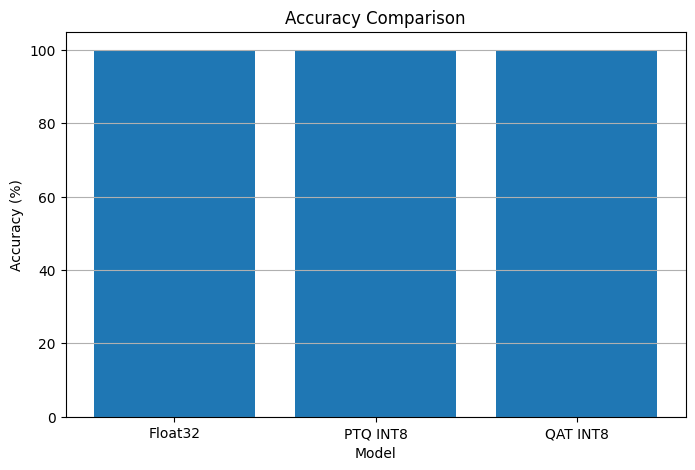

In [26]:
# ACCURACY COMPARISON

plt.figure(figsize=(8, 5))

plt.bar(
    final_comparison["Model"],
    final_comparison["Accuracy (%)"]
)

plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison")

plt.grid(axis="y")

plt.show()

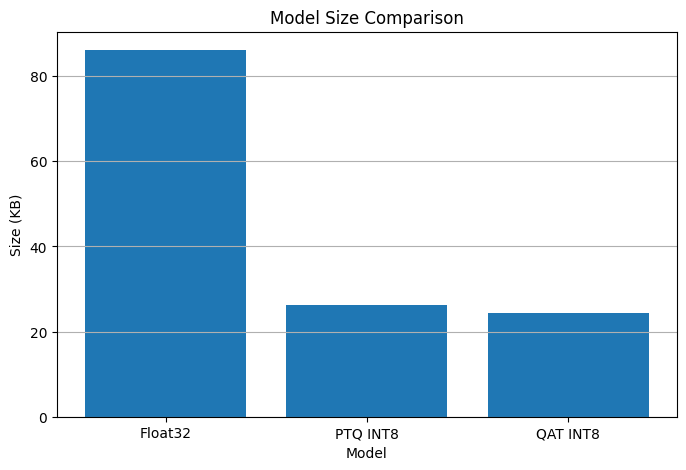

In [27]:
# MODEL SIZE COMPARISON

plt.figure(figsize=(8, 5))

plt.bar(
    final_comparison["Model"],
    final_comparison["Model Size (KB)"]
)

plt.xlabel("Model")
plt.ylabel("Size (KB)")
plt.title("Model Size Comparison")

plt.grid(axis="y")

plt.show()

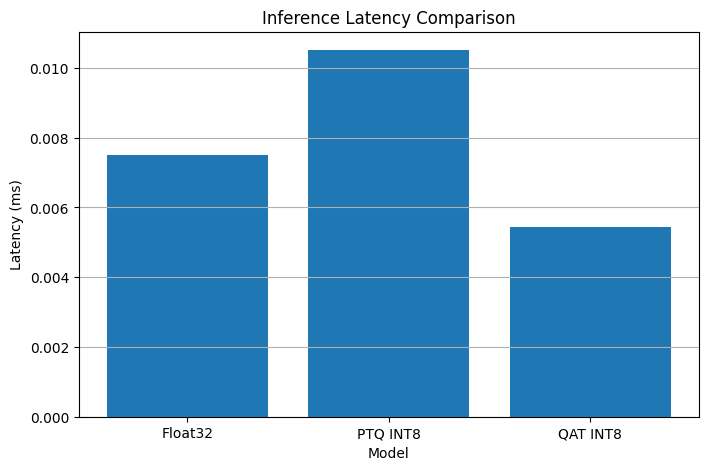

In [28]:
# INFERENCE LATENCY COMPARISON

plt.figure(figsize=(8, 5))

plt.bar(
    final_comparison["Model"],
    final_comparison["Latency (ms)"]
)

plt.xlabel("Model")
plt.ylabel("Latency (ms)")
plt.title("Inference Latency Comparison")

plt.grid(axis="y")

plt.show()

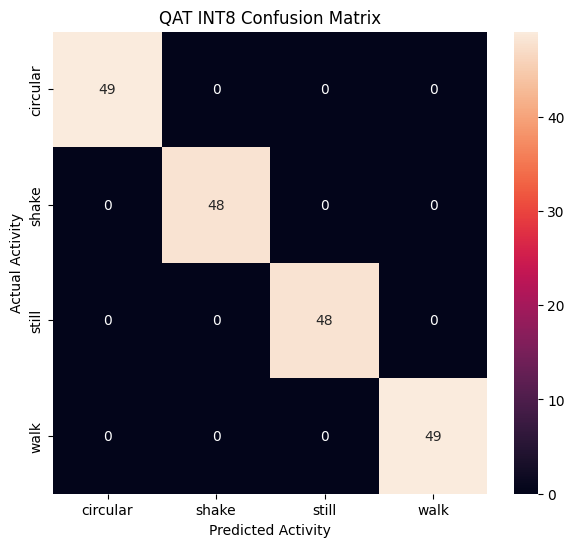

QAT INT8 CLASSIFICATION REPORT
              precision    recall  f1-score   support

    circular       1.00      1.00      1.00        49
       shake       1.00      1.00      1.00        48
       still       1.00      1.00      1.00        48
        walk       1.00      1.00      1.00        49

    accuracy                           1.00       194
   macro avg       1.00      1.00      1.00       194
weighted avg       1.00      1.00      1.00       194



In [29]:
# CONFUSION MATRIX & CLASSIFICATION REPORT

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import seaborn as sns

# Generate predictions using the QAT INT8 model

qat_predictions = []

for i in range(len(X_test)):

    sample = X_test[i:i+1].astype(np.float32)

    quantized_sample = np.round(
        sample / qat_input_scale
        + qat_input_zero_point
    )

    quantized_sample = np.clip(
        quantized_sample,
        -128,
        127
    ).astype(np.int8)

    qat_interpreter.set_tensor(
        qat_input_details[0]["index"],
        quantized_sample
    )

    qat_interpreter.invoke()

    output = qat_interpreter.get_tensor(
        qat_output_details[0]["index"]
    )

    prediction = np.argmax(output)

    qat_predictions.append(prediction)

qat_predictions = np.array(qat_predictions)

# Create the confusion matrix

cm = confusion_matrix(
    y_test,
    qat_predictions
)

# Display the confusion matrix

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.title("QAT INT8 Confusion Matrix")

plt.show()

# Display classification report

print("QAT INT8 CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        qat_predictions,
        target_names=label_encoder.classes_
    )
)

In [30]:
# SAVE MODELS & RESULTS

import os
import pandas as pd

# Create a folder for the final models

os.makedirs("tinyml_models", exist_ok=True)

# Copy the three TFLite models into the folder

with open(
    "tinyml_models/float32_baseline.tflite",
    "wb"
) as f:

    with open(
        "float32_baseline.tflite",
        "rb"
    ) as source:

        f.write(source.read())


with open(
    "tinyml_models/ptq_full_int8.tflite",
    "wb"
) as f:

    with open(
        "ptq_full_int8.tflite",
        "rb"
    ) as source:

        f.write(source.read())


with open(
    "tinyml_models/qat_full_int8.tflite",
    "wb"
) as f:

    with open(
        "qat_full_int8.tflite",
        "rb"
    ) as source:

        f.write(source.read())

# Save the final comparison table

final_comparison.to_csv(
    "tinyml_models/model_comparison.csv",
    index=False
)

# Display saved files

print("Saved files:")

for file in os.listdir("tinyml_models"):

    file_path = os.path.join(
        "tinyml_models",
        file
    )

    file_size = os.path.getsize(
        file_path
    ) / 1024

    print(
        f"{file}: {file_size:.2f} KB"
    )

Saved files:
float32_baseline.tflite: 86.14 KB
qat_full_int8.tflite: 24.33 KB
ptq_full_int8.tflite: 26.22 KB
model_comparison.csv: 0.18 KB
